In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

train    = pd.read_csv('train.csv')
test     = pd.read_csv('test.csv')
labels   = pd.read_csv('train_labels.csv')
pairs    = pd.read_csv('target_pairs.csv')

print("Train shape  :", train.shape)
print("Test shape   :", test.shape)
print("Labels shape :", labels.shape)
print("Pairs shape  :", pairs.shape)
print("\nSample pairs:")
print(pairs.head(10))

Train shape  : (1961, 558)
Test shape   : (134, 559)
Labels shape : (1961, 425)
Pairs shape  : (424, 3)

Sample pairs:
     target  lag                                               pair
0  target_0    1                              US_Stock_VT_adj_close
1  target_1    1               LME_PB_Close - US_Stock_VT_adj_close
2  target_2    1                        LME_CA_Close - LME_ZS_Close
3  target_3    1                        LME_AH_Close - LME_ZS_Close
4  target_4    1     LME_AH_Close - JPX_Gold_Standard_Futures_Close
5  target_5    1  LME_ZS_Close - JPX_Platinum_Standard_Futures_C...
6  target_6    1                        LME_PB_Close - LME_AH_Close
7  target_7    1              LME_ZS_Close - US_Stock_VYM_adj_close
8  target_8    1  US_Stock_IEMG_adj_close - JPX_Gold_Standard_Fu...
9  target_9    1                           FX_AUDJPY - LME_PB_Close


In [2]:
def get_pair_columns(pair_str, train_cols):
    """Extract actual column names from pair string like 'LME_AH_Close - LME_ZS_Close'"""
    if ' - ' in pair_str:
        col1, col2 = pair_str.split(' - ', 1)
        col1, col2 = col1.strip(), col2.strip()
        return col1, col2
    else:
        return pair_str.strip(), None

# Test
sample = pairs['pair'].iloc[0]
print(f"Pair: {sample}")
print(f"Parsed: {get_pair_columns(sample, train.columns)}")

Pair: US_Stock_VT_adj_close
Parsed: ('US_Stock_VT_adj_close', None)


In [3]:
def build_features(df, col1, col2, lags=[1,2,3,4,5,10,20]):
    """Build lag features from pair columns"""
    feats = pd.DataFrame(index=df.index)

    # Raw values
    if col1 in df.columns:
        feats[f'{col1}_raw'] = df[col1]
        for lag in lags:
            feats[f'{col1}_lag{lag}'] = df[col1].shift(lag)
        feats[f'{col1}_ret1']  = df[col1].pct_change(1)
        feats[f'{col1}_ret5']  = df[col1].pct_change(5)
        feats[f'{col1}_ret10'] = df[col1].pct_change(10)
        feats[f'{col1}_ma5']   = df[col1].rolling(5).mean()
        feats[f'{col1}_ma20']  = df[col1].rolling(20).mean()
        feats[f'{col1}_std10'] = df[col1].rolling(10).std()

    if col2 is not None and col2 in df.columns:
        feats[f'{col2}_raw'] = df[col2]
        for lag in lags:
            feats[f'{col2}_lag{lag}'] = df[col2].shift(lag)
        feats[f'{col2}_ret1']  = df[col2].pct_change(1)
        feats[f'{col2}_ret5']  = df[col2].pct_change(5)
        feats[f'{col2}_ret10'] = df[col2].pct_change(10)
        feats[f'{col2}_ma5']   = df[col2].rolling(5).mean()
        feats[f'{col2}_ma20']  = df[col2].rolling(20).mean()

        # Spread features
        if col1 in df.columns:
            feats['spread']      = df[col1] - df[col2]
            feats['spread_lag1'] = feats['spread'].shift(1)
            feats['ratio']       = df[col1] / (df[col2] + 1e-8)

    # Time features
    feats['date_id'] = df['date_id']

    return feats

print("Feature builder ready!")

Feature builder ready!


In [4]:
# Merge train + labels
full_train = train.merge(labels, on='date_id', how='inner')

# Split: gunakan 80% awal sebagai train, 20% akhir sebagai val
split_idx  = int(len(full_train) * 0.8)
train_data = full_train.iloc[:split_idx]
val_data   = full_train.iloc[split_idx:]

predictions_test = {}
val_maes = []

print(f"Training {len(pairs)} targets...")
print("="*55)

for i, row in pairs.iterrows():
    target_name = row['target']
    pair_str    = row['pair']
    lag         = row['lag']

    col1, col2 = get_pair_columns(pair_str, train.columns)

    # Build features
    X_tr  = build_features(train_data, col1, col2).fillna(0)
    X_val = build_features(val_data, col1, col2).fillna(0)
    X_te  = build_features(test, col1, col2).fillna(0)

    y_tr  = train_data[target_name]
    y_val = val_data[target_name]

    # Drop rows with NaN target
    mask_tr  = y_tr.notna()
    mask_val = y_val.notna()

    if mask_tr.sum() < 50:
        # Not enough data — predict mean
        predictions_test[target_name] = np.full(len(test), y_tr.mean())
        continue

    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=31,
        random_state=42,
        verbose=0
    )
    model.fit(X_tr[mask_tr], y_tr[mask_tr])

    if mask_val.sum() > 0:
        val_pred = model.predict(X_val[mask_val])
        mae = mean_absolute_error(y_val[mask_val], val_pred)
        val_maes.append(mae)

    predictions_test[target_name] = model.predict(X_te)

    if (i+1) % 50 == 0:
        print(f"  [{i+1}/424] Done | Avg Val MAE so far: {np.mean(val_maes):.6f}")

print("="*55)
print(f"Training complete!")
print(f"Overall Avg Val MAE: {np.mean(val_maes):.6f}")

Training 424 targets...
  [50/424] Done | Avg Val MAE so far: 0.013975
  [100/424] Done | Avg Val MAE so far: 0.014546
  [150/424] Done | Avg Val MAE so far: 0.016223
  [200/424] Done | Avg Val MAE so far: 0.017466
  [250/424] Done | Avg Val MAE so far: 0.018803
  [300/424] Done | Avg Val MAE so far: 0.019913
  [350/424] Done | Avg Val MAE so far: 0.021066
  [400/424] Done | Avg Val MAE so far: 0.022278
Training complete!
Overall Avg Val MAE: 0.022752


In [5]:
# Build submission dataframe
pred_df = pd.DataFrame(predictions_test)
pred_df.insert(0, 'date_id', test['date_id'].values)

# Format: long format — date_id, target, prediction
submission_rows = []
for _, row in pairs.iterrows():
    target = row['target']
    lag    = row['lag']
    preds  = predictions_test[target]
    for date_id, pred in zip(test['date_id'].values, preds):
        submission_rows.append({
            'date_id': date_id,
            'target' : target,
            'prediction': pred
        })

submission = pd.DataFrame(submission_rows)
submission.to_csv('submission.csv', index=False)

print("Submission preview:")
print(submission.head(10))
print(f"\nSubmission shape: {submission.shape}")
print(f"Unique targets  : {submission['target'].nunique()}")

from google.colab import files
files.download('submission.csv')

Submission preview:
   date_id    target  prediction
0     1827  target_0    0.009589
1     1828  target_0    0.014177
2     1829  target_0   -0.001485
3     1830  target_0    0.008853
4     1831  target_0   -0.002573
5     1832  target_0    0.001249
6     1833  target_0    0.002316
7     1834  target_0    0.001060
8     1835  target_0   -0.001389
9     1836  target_0    0.001106

Submission shape: (56816, 3)
Unique targets  : 424


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

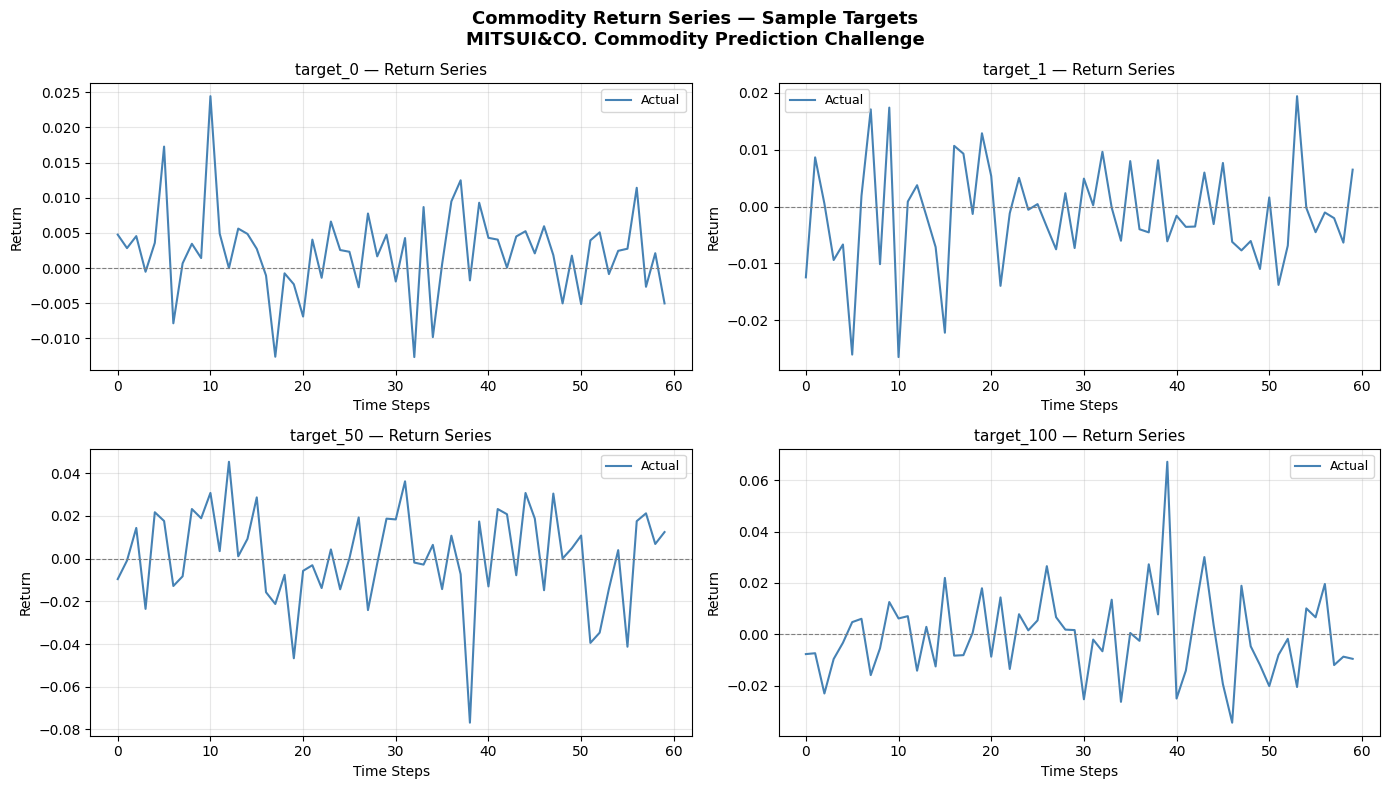

Plot saved!


In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Plot sample predictions untuk beberapa targets
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sample_targets = ['target_0', 'target_1', 'target_50', 'target_100']

for ax, tgt in zip(axes.flatten(), sample_targets):
    # Actual values dari validation set
    actual = val_data[tgt].dropna().values[-60:]
    ax.plot(actual, label='Actual', color='steelblue', linewidth=1.5)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(f'{tgt} — Return Series', fontsize=11)
    ax.set_xlabel('Time Steps')
    ax.set_ylabel('Return')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Commodity Return Series — Sample Targets\nMITSUI&CO. Commodity Prediction Challenge',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('commodity_returns.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved!")